Assignment seasonal

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

data = pd.read_csv("Walmart_Sales.csv")
data.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


<Axes: xlabel='Date'>

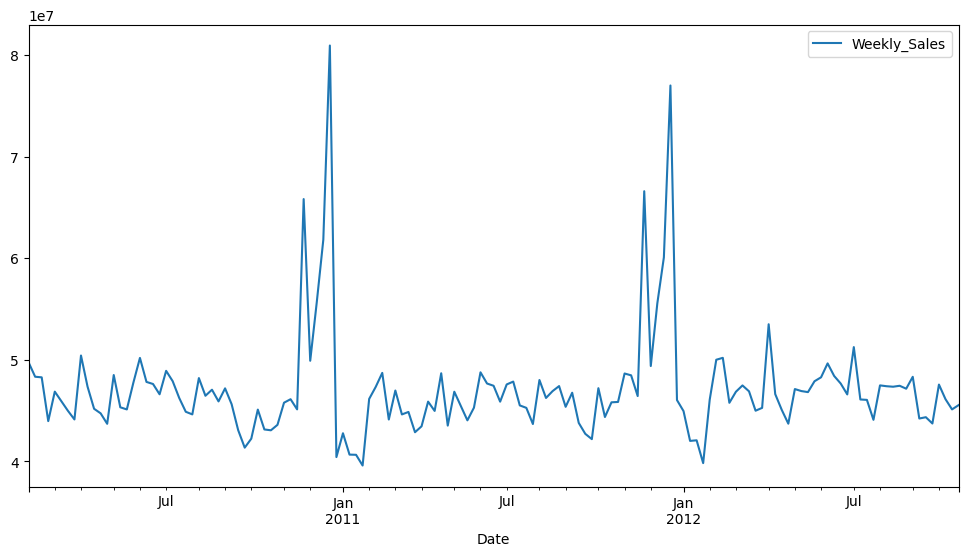

In [21]:
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')
df_agg = data.groupby('Date')['Weekly_Sales'].sum().reset_index()
df_agg = df_agg.set_index('Date').sort_index()
df_agg = df_agg.asfreq('W-FRI')

df_agg.plot(kind='line', figsize=(12, 6))

In [22]:
fourier_terms = Fourier(period=52.14, order=3)

dp_terpadu = DeterministicProcess(
    index=df_agg.index,
    constant=True,
    order=3, 
    additional_terms=[fourier_terms],
    drop=True
)

X_fitur = dp_terpadu.in_sample()
y_target = df_agg['Weekly_Sales']

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_fitur, y_target, test_size=0.2, shuffle=False)

model_musiman = LinearRegression(fit_intercept=False)
model_musiman.fit(X_train, y_train)

LinearRegression(fit_intercept=False)

In [24]:
prediksi_uji = model_musiman.predict(X_test)
error_mae = mean_absolute_error(y_test, prediksi_uji)

print("\n=== HASIL EVALUASI ===")
print(f"Mean Absolute Error (MAE): {error_mae:,.2f}")


=== HASIL EVALUASI ===
Mean Absolute Error (MAE): 2,121,004.44


In [25]:
model_musiman = LinearRegression(fit_intercept=False)
model_musiman.fit(X_fitur, y_target)

langkah_depan = 12 # Ramalan 12 minggu ke depan

X_masa_depan = dp_terpadu.out_of_sample(steps=langkah_depan)
prediksi_masa_depan = model_musiman.predict(X_masa_depan)

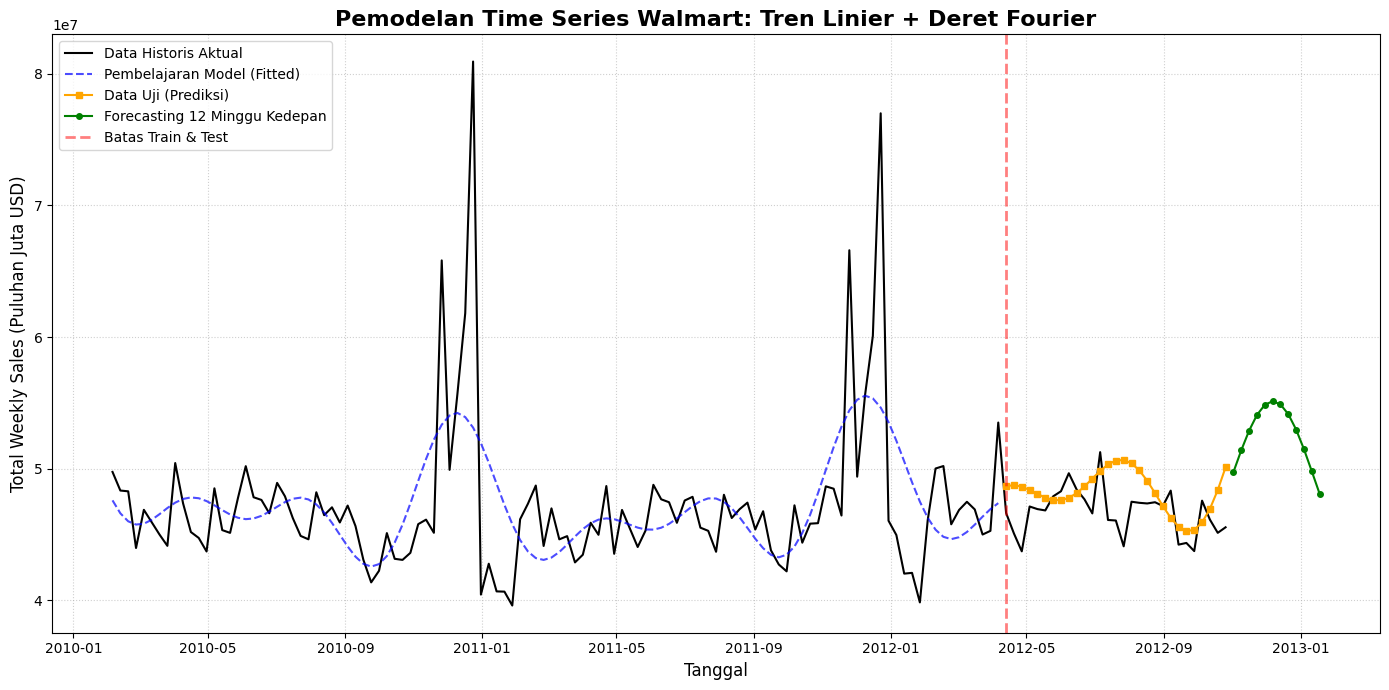

In [26]:
# Konfigurasi Grafik Visualisasi
plt.figure(figsize=(14, 7))

# Plot 1: Data Aktual & Area Pembelajaran (Training)
plt.plot(df_agg.index, df_agg['Weekly_Sales'], color='black', label='Data Historis Aktual')
plt.plot(X_train.index, model_musiman.predict(X_train), color='blue', linestyle='--', alpha=0.7, label='Pembelajaran Model (Fitted)')

# Plot 2: Area Prediksi (Testing)
plt.plot(X_test.index, prediksi_uji, color='orange', marker='s', markersize=4, label='Data Uji (Prediksi)')

# Plot 3: Area Peramalan (Forecasting)
plt.plot(X_masa_depan.index, prediksi_masa_depan, color='green', marker='o', markersize=4, label='Forecasting 12 Minggu Kedepan')

# Plot 4: Garis Batas Waktu
plt.axvline(x=X_test.index[0], color='red', linestyle='--', linewidth=2, alpha=0.5, label='Batas Train & Test')

# Estetika Grafik
plt.title('Pemodelan Time Series Walmart: Tren Linier + Deret Fourier', fontsize=16, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Total Weekly Sales (Puluhan Juta USD)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Menampilkan grafik
plt.show()

Siklus

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.deterministic import DeterministicProcess

dates = pd.date_range("2023-01-01", periods=100, freq="D")

np.random.seed(42)
tren_sebenarnya = np.linspace(10, 50, 100) # Tren naik perlahan dari 10 ke 50
noise = np.random.normal(0, 3, 100)        
y = pd.Series(tren_sebenarnya + noise, index=dates, name="Nilai_Observasi")
print(y.head())

dp = DeterministicProcess(index=y.index, order=1, constant=True)
X_trend = dp.in_sample()

model_trend = LinearRegression()
model_trend.fit(X_trend, y)
y_trend_pred = pd.Series(model_trend.predict(X_trend), index=X_trend.index)
print(y_trend_pred.head())  

y_detrended = y - y_trend_pred
y_detrended.name = "Detrended_Series"
print(y_detrended.head())

2023-01-01    11.490142
2023-01-02     9.989248
2023-01-03    12.751146
2023-01-04    15.781211
2023-01-05    10.913701
Freq: D, Name: Nilai_Observasi, dtype: float64
2023-01-01     9.481561
2023-01-02     9.889782
2023-01-03    10.298002
2023-01-04    10.706222
2023-01-05    11.114442
Freq: D, dtype: float64
2023-01-01    2.008581
2023-01-02    0.099466
2023-01-03    2.453145
2023-01-04    5.074989
2023-01-05   -0.200741
Freq: D, Name: Detrended_Series, dtype: float64


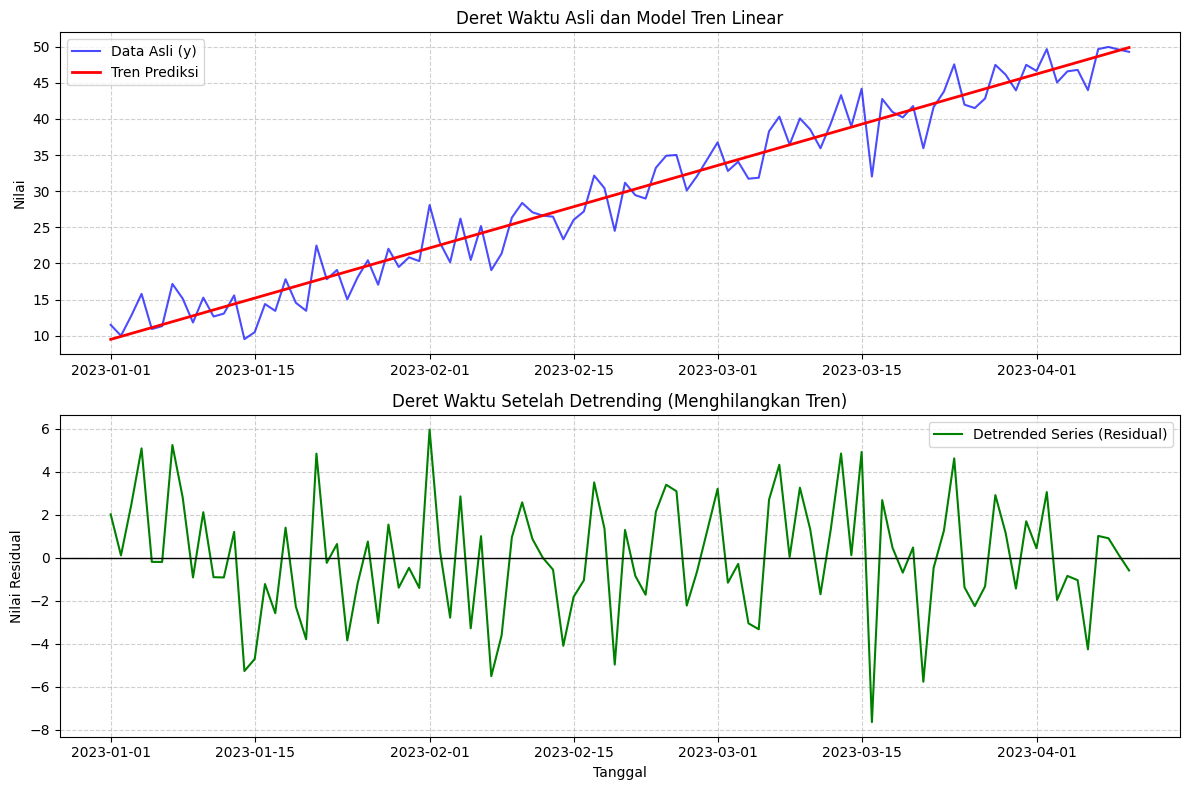

In [28]:
plt.figure(figsize=(12, 8))

# Grafik Atas: Data Asli vs Tren yang Ditemukan Model
plt.subplot(2, 1, 1)
plt.plot(y, label='Data Asli (y)', color='blue', alpha=0.7)
plt.plot(y_trend_pred, label='Tren Prediksi', color='red', linewidth=2)
plt.title('Deret Waktu Asli dan Model Tren Linear')
plt.ylabel('Nilai')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Grafik Bawah: Hasil Detrending (Sisa / Residual)
plt.subplot(2, 1, 2)
plt.plot(y_detrended, label='Detrended Series (Residual)', color='green')
plt.axhline(0, color='black', linestyle='-', linewidth=1) # Garis nol sebagai referensi
plt.title('Deret Waktu Setelah Detrending (Menghilangkan Tren)')
plt.ylabel('Nilai Residual')
plt.xlabel('Tanggal')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Tabel Data dengan Fitur Lag:
                   y     lag_1     lag_2
2023-01-01  2.008581       NaN       NaN
2023-01-02  0.099466  2.008581       NaN
2023-01-03  2.453145  0.099466  2.008581
2023-01-04  5.074989  2.453145  0.099466
2023-01-05 -0.200741  5.074989  2.453145
----------------------------------------


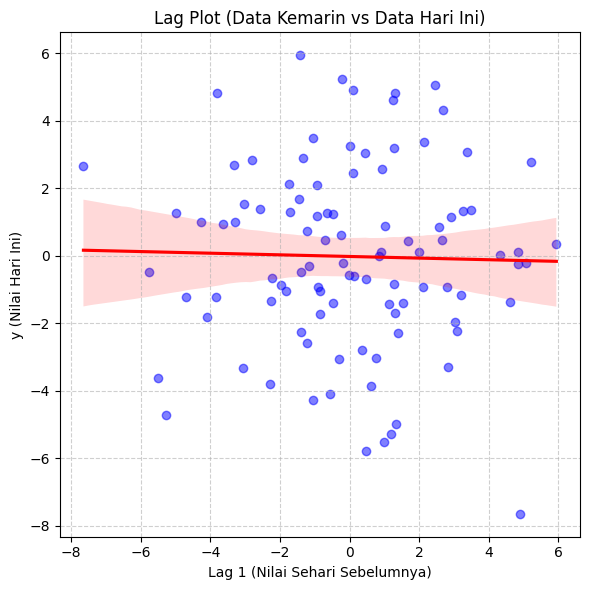

In [29]:
import seaborn as sns

# Membuat Lag 1 dan Lag 2 menggunakan method shift()
df_lag = pd.DataFrame({
    'y': y_detrended,                # Data hari ini
    'lag_1': y_detrended.shift(1),   # Data kemarin (mundur 1 langkah)
    'lag_2': y_detrended.shift(2)    # Data lusa kemarin (mundur 2 langkah)
})

print("Tabel Data dengan Fitur Lag:")
print(df_lag.head())
print("-" * 40)

plt.figure(figsize=(6, 6))

sns.regplot(
    x='lag_1', 
    y='y', 
    data=df_lag, 
    scatter_kws={'alpha': 0.5, 'color': 'blue'}, 
    line_kws={'color': 'red'}
)

plt.title('Lag Plot (Data Kemarin vs Data Hari Ini)')
plt.xlabel('Lag 1 (Nilai Sehari Sebelumnya)')
plt.ylabel('y (Nilai Hari Ini)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

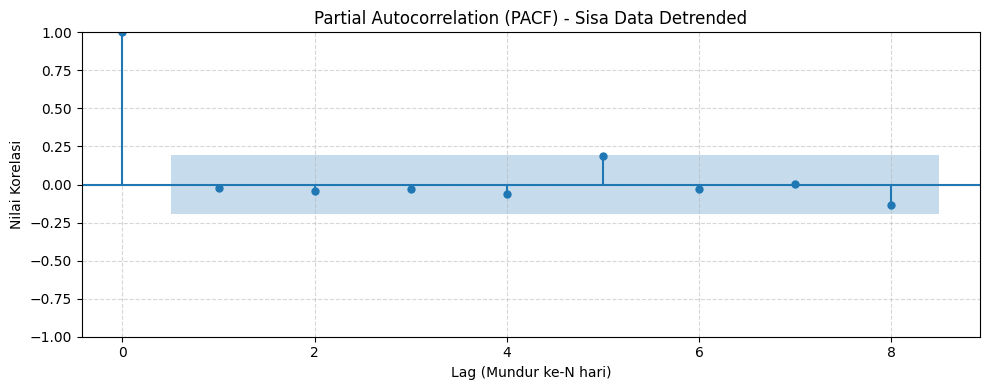

In [30]:
from statsmodels.graphics.tsaplots import plot_pacf

fig, ax = plt.subplots(figsize=(10, 4))

# Membuat grafik PACF
plot_pacf(y_detrended.dropna(), lags=8, ax=ax)

plt.title("Partial Autocorrelation (PACF) - Sisa Data Detrended")
plt.xlabel("Lag (Mundur ke-N hari)")
plt.ylabel("Nilai Korelasi")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

            Search_Volume
2023-01-01     524.835708
2023-01-02     493.086785
2023-01-03     532.384427
2023-01-04     576.151493
2023-01-05     488.292331
Tabel Data Siap Model (5 Baris Pertama):
            Penjualan_y  search_lag_1  search_lag_2
2023-01-03   292.424926    493.086785    524.835708
2023-01-04   311.407883    532.384427    493.086785
2023-01-05   344.078039    576.151493    532.384427
2023-01-06   297.015907    488.292331    576.151493
2023-01-07   311.837750    488.293152    488.292331
--------------------------------------------------


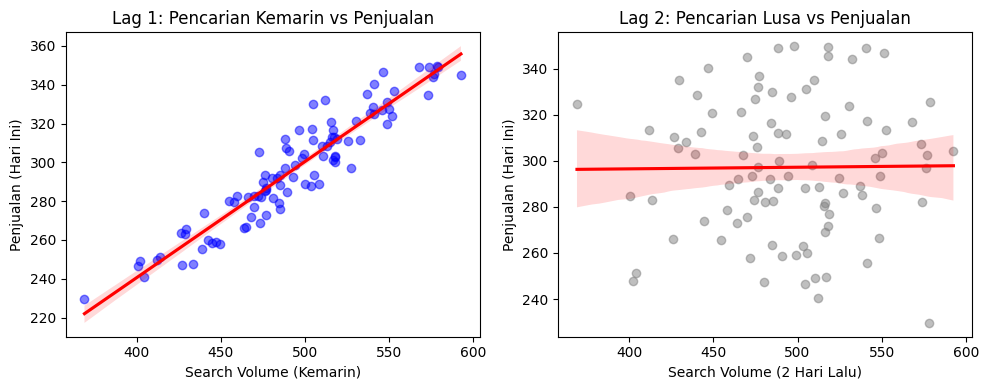

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dates = pd.date_range("2023-01-01", periods=100, freq="D")
np.random.seed(42)

search_volume = np.random.normal(500, 50, 100) # Rata-rata 500 pencarian/hari
df_external = pd.DataFrame({'Search_Volume': search_volume}, index=dates)
print(df_external.head())

penjualan = (0.6 * df_external['Search_Volume'].shift(1)) + np.random.normal(0, 10, 100)
y = pd.Series(penjualan, index=dates, name="Penjualan_y")

X_leading = pd.DataFrame({
    'search_lag_1': df_external['Search_Volume'].shift(1), # Pencarian Kemarin
    'search_lag_2': df_external['Search_Volume'].shift(2)  # Pencarian Lusa Kemarin
})

df_model = pd.concat([y, X_leading], axis=1)
df_model = df_model.dropna()

print("Tabel Data Siap Model (5 Baris Pertama):")
print(df_model.head())
print("-" * 50)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.regplot(x='search_lag_1', y='Penjualan_y', data=df_model, 
            scatter_kws={'alpha':0.5, 'color':'blue'}, line_kws={'color':'red'})
plt.title('Lag 1: Pencarian Kemarin vs Penjualan')
plt.xlabel('Search Volume (Kemarin)')
plt.ylabel('Penjualan (Hari Ini)')

plt.subplot(1, 2, 2)
sns.regplot(x='search_lag_2', y='Penjualan_y', data=df_model, 
            scatter_kws={'alpha':0.5, 'color':'gray'}, line_kws={'color':'red'})
plt.title('Lag 2: Pencarian Lusa vs Penjualan')
plt.xlabel('Search Volume (2 Hari Lalu)')
plt.ylabel('Penjualan (Hari Ini)')

plt.tight_layout()
plt.show()

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.deterministic import DeterministicProcess

# Membuat data deret waktu sintetik (100 hari)
np.random.seed(42)
time_index = pd.date_range("2023-01-01", periods=100, freq="D")

# Komponen Target (Kunjungan Pasien) = Tren + Siklus + Noise
trend = np.linspace(10, 50, 100)
cycle = np.sin(np.linspace(0, 20, 100)) * 15
noise = np.random.normal(0, 2, 100)
target_visits = trend + cycle + noise

# Komponen Leading Indicator (Pencarian Google) = Siklus yang terjadi 2 hari lebih awal + Noise
leading_cycle = np.sin(np.linspace(0, 20, 100) + 0.5) * 20 
search_volume = trend + leading_cycle + np.random.normal(0, 3, 100)

df = pd.DataFrame({
    'Visits': target_visits,
    'Search_Volume': search_volume
}, index=time_index)

df

,Visits,Search_Volume
2023-01-01,10.993428,15.342399
2023-01-02,13.137245,22.057335
2023-01-03,18.000507,25.496579
2023-01-04,22.802693,26.684090
2023-01-05,21.992293,30.446071
...,...,...
2023-04-06,50.492521,64.464159
2023-04-07,57.148481,63.428605
2023-04-08,59.899074,68.609984
2023-04-09,61.793652,69.621022


In [34]:
# Membuat fitur waktu untuk tren linear
dp = DeterministicProcess(index=df.index, order=1, constant=True)
X_time = dp.in_sample()

# Fit target untuk mendapatkan tren
model_trend = LinearRegression()
model_trend.fit(X_time, df['Visits'])
trend_pred = pd.Series(model_trend.predict(X_time), index=df.index)

# Proses Detrending
df['Visits_Detrended'] = df['Visits'] - trend_pred

In [35]:
# Ekstraksi fitur Lag untuk siklus internal
df['Lag_1_Visits'] = df['Visits_Detrended'].shift(1)
df['Lag_2_Visits'] = df['Visits_Detrended'].shift(2)

# Ekstraksi fitur Lag untuk Leading Indicator
df['Lag_1_Search'] = df['Search_Volume'].shift(1)
df['Lag_2_Search'] = df['Search_Volume'].shift(2)

# Membuang baris yang memiliki nilai NaN akibat pergeseran lag
df_model = df.dropna().copy()

Assignment

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess
from statsmodels.graphics.tsaplots import plot_pacf

df = pd.read_csv('coffee_sales.csv')
df['date'] = pd.to_datetime(df['date'])
df.head()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


In [46]:
daily_sales = df.groupby('date')['money'].sum()
daily_sales.sort_index(inplace=True)
daily_sales = daily_sales.asfreq('D').ffill()
print(daily_sales.head())

date
2024-03-01    396.3
2024-03-02    228.1
2024-03-03    349.1
2024-03-04    135.2
2024-03-05    338.5
Freq: D, Name: money, dtype: float64


            const  trend
date                    
2024-03-01    1.0    1.0
2024-03-02    1.0    2.0
2024-03-03    1.0    3.0
2024-03-04    1.0    4.0
2024-03-05    1.0    5.0
date
2024-03-01    217.422399
2024-03-02    217.858926
2024-03-03    218.295452
2024-03-04    218.731979
2024-03-05    219.168506
Freq: D, dtype: float64
date
2024-03-01    178.877601
2024-03-02     10.241074
2024-03-03    130.804548
2024-03-04    -83.531979
2024-03-05    119.331494
Freq: D, dtype: float64


<Axes: xlabel='date'>

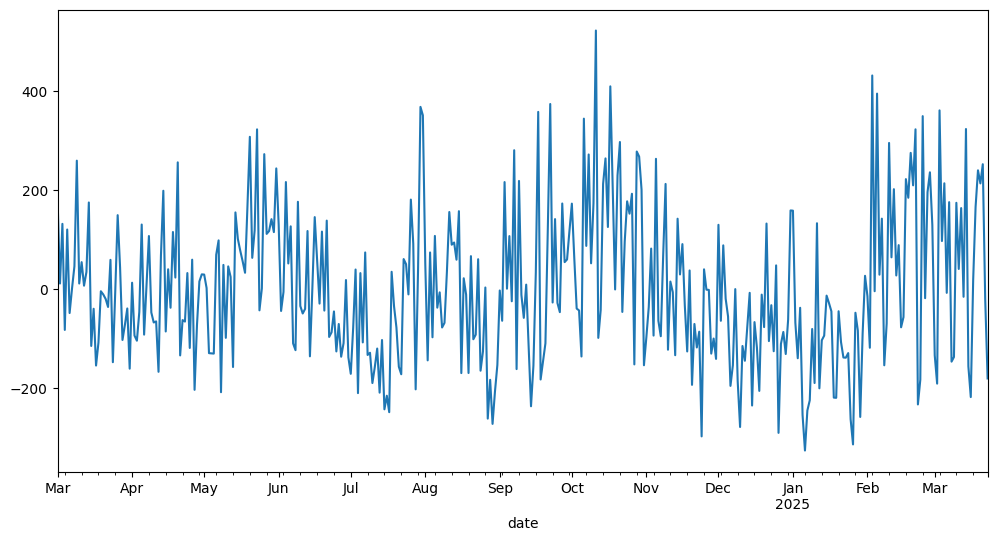

In [51]:
dp = DeterministicProcess(index=daily_sales.index, order=1, constant=True)
X_time = dp.in_sample()
print(X_time.head())

trend_model = LinearRegression()
trend_model.fit(X_time, daily_sales)
trend_pred = pd.Series(trend_model.predict(X_time), index=daily_sales.index)
print(trend_pred.head())

detrended_sales = daily_sales - trend_pred
print(detrended_sales.head())

detrended_sales.plot(kind='line', figsize=(12,6))

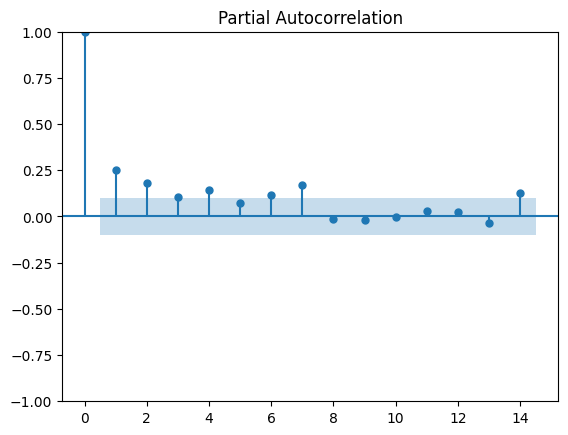

In [52]:
plot_pacf(detrended_sales.dropna(), lags=14)
plt.show()

In [54]:
df_features = pd.DataFrame({
    'y': detrended_sales,
    'lag_1': detrended_sales.shift(1),
    'lag_2': detrended_sales.shift(2),
    'lag_7': detrended_sales.shift(7)
})

df_features.dropna(inplace=True)
df_features.head()

,y,lag_1,lag_2,lag_7
date,,,,
2024-03-08,45.021914,0.058441,-49.405032,178.877601
2024-03-09,258.485388,45.021914,0.058441,10.241074
2024-03-10,10.248861,258.485388,45.021914,130.804548
2024-03-11,53.412334,10.248861,258.485388,-83.531979
2024-03-12,5.875808,53.412334,10.248861,119.331494


Mean Absolute Error (MAE) pada Data Uji: 138.66


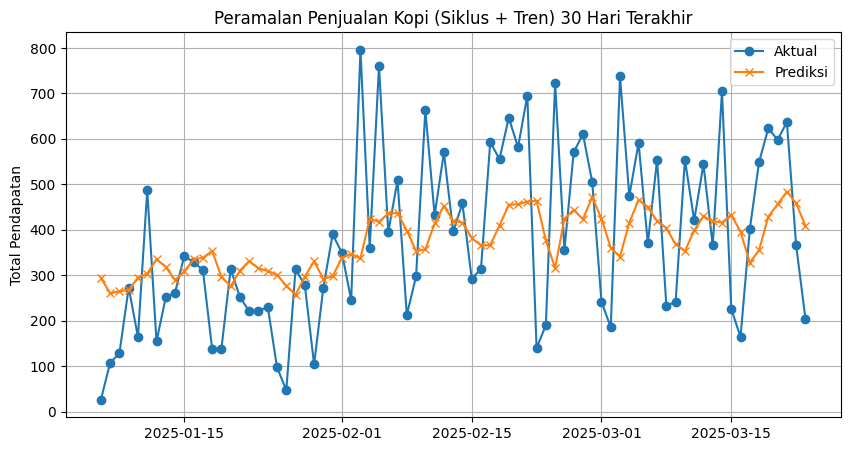

In [58]:
from sklearn.model_selection import train_test_split

x = df_features.drop(columns=['y'])
y = df_features['y']

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, shuffle=False)

model_cycle = LinearRegression(fit_intercept=False)
model_cycle.fit(X_train, y_train)

cycle_pred = pd.Series(model_cycle.predict(X_test), index=X_test.index)

final_pred = cycle_pred + trend_pred.loc[X_test.index]
actual_test = daily_sales.loc[X_test.index]
error_mae = mean_absolute_error(actual_test, final_pred)
print(f"Mean Absolute Error (MAE) pada Data Uji: {error_mae:.2f}")

plt.figure(figsize=(10, 5))
plt.plot(actual_test.index, actual_test, label='Aktual', marker='o')
plt.plot(final_pred.index, final_pred, label='Prediksi', marker='x')
plt.title('Peramalan Penjualan Kopi (Siklus + Tren) 30 Hari Terakhir')
plt.ylabel('Total Pendapatan')
plt.legend()
plt.grid(True)
plt.show()